# 08. Implementación del modelo basado en distribución de Poisson
En este cuaderno implemento un modelo probabilístico basado en la distribución de Poisson para estimar el número de goles que puede anotar cada equipo en un partido de la Liga Panameña de Fútbol.
A diferencia de Regresión Logística, Random Forest y XGBoost, no planteo inicialmente el problema como una clasificación directa entre victoria local, empate y victoria visitante. En su lugar, construyo dos modelos: uno para estimar los goles esperados del equipo local y otro para estimar los goles esperados del equipo visitante.
Represento estas cantidades mediante los parámetros `lambda_local` y `lambda_visitante`. Posteriormente utilizo la distribución de Poisson para calcular la probabilidad de diferentes marcadores posibles.

A partir de la matriz de probabilidades de marcadores obtengo la probabilidad agregada de victoria local, empate y victoria visitante, así como el marcador exacto con mayor probabilidad.

Mantengo la misma separación temporal utilizada en los modelos anteriores. Utilizo los partidos históricos hasta 2024 para entrenamiento, los encuentros de 2025 para validación y conservo los partidos correspondientes a 2026 y 2026/2027 completamente separados hasta finalizar la selección del modelo.

# Celda 2  Librerías

In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import poisson

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    OneHotEncoder,
    MinMaxScaler
)

from sklearn.linear_model import PoissonRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_poisson_deviance,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    log_loss,
    classification_report,
    confusion_matrix
)

pd.set_option("display.max_columns", 150)
pd.set_option("display.max_rows", 100)

print("Librerías cargadas correctamente.")

Librerías cargadas correctamente.


# Celda 3 Carga de datos
## 1. Carga de los conjuntos temporales
Cargo los mismos conjuntos utilizados anteriormente para mantener una evaluación temporal consistente entre todos los modelos.
Aunque Poisson tiene un objetivo diferente a los clasificadores supervisados, mantengo exactamente los mismos partidos de entrenamiento, validación y prueba.

In [3]:
ROOT = Path("..").resolve()

PROCESSED_DIR = ROOT / "data" / "processed"
FIGURES_DIR = ROOT / "figures"
MODELS_DIR = ROOT / "models"

FIGURES_DIR.mkdir(
    parents=True,
    exist_ok=True
)

MODELS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

TRAIN_PATH = PROCESSED_DIR / "lpf_train.csv"
VALIDACION_PATH = PROCESSED_DIR / "lpf_validacion.csv"
TEST_PATH = PROCESSED_DIR / "lpf_test.csv"

df_train = pd.read_csv(
    TRAIN_PATH,
    encoding="utf-8-sig",
    parse_dates=["fecha_partido"]
)

df_validacion = pd.read_csv(
    VALIDACION_PATH,
    encoding="utf-8-sig",
    parse_dates=["fecha_partido"]
)

df_test = pd.read_csv(
    TEST_PATH,
    encoding="utf-8-sig",
    parse_dates=["fecha_partido"]
)

print("Entrenamiento:", df_train.shape)
print("Validación:", df_validacion.shape)
print("Prueba:", df_test.shape)

Entrenamiento: (1869, 55)
Validación: (206, 55)
Prueba: (151, 55)


# Celda 4 Verificación temporal
### 1.1. Verificación temporal
Compruebo nuevamente que los encuentros utilizados para entrenamiento sean anteriores a validación y que el conjunto de prueba permanezca cronológicamente posterior.
Esta separación evita utilizar información futura durante la estimación de los parámetros del modelo.

In [4]:
print(
    "Train:",
    df_train["fecha_partido"].min(),
    "→",
    df_train["fecha_partido"].max()
)

print(
    "Validación:",
    df_validacion["fecha_partido"].min(),
    "→",
    df_validacion["fecha_partido"].max()
)

print(
    "Prueba:",
    df_test["fecha_partido"].min(),
    "→",
    df_test["fecha_partido"].max()
)

assert (
    df_train["fecha_partido"].max()
    <
    df_validacion["fecha_partido"].min()
)

assert (
    df_validacion["fecha_partido"].max()
    <
    df_test["fecha_partido"].min()
)

print("\nSeparación temporal correcta.")

Train: 2014-07-18 00:00:00 → 2024-11-30 00:00:00
Validación: 2025-01-17 00:00:00 → 2025-11-29 00:00:00
Prueba: 2026-01-16 00:00:00 → 2026-09-14 00:00:00

Separación temporal correcta.


# Celda 5  Predictores y objetivos
## 2. Definición de variables predictoras y objetivos
Utilizo las mismas 48 características prepartido empleadas en los clasificadores anteriores.
Sin embargo, en este caso utilizo dos variables objetivo diferentes:

- `home_team_goal_count`: cantidad de goles anotados por el equipo local.
- `away_team_goal_count`: cantidad de goles anotados por el equipo visitante.

Los goles del propio partido continúan completamente excluidos de las variables predictoras.

De esta manera, para cada encuentro estimaré dos tasas de gol independientes que posteriormente utilizaré dentro de la distribución de Poisson.

In [5]:
columnas_no_predictoras = [
    "registro_id",
    "fecha_partido",
    "temporada",
    "home_team_goal_count",
    "away_team_goal_count",
    "total_goal_count",
    "resultado"
]

columnas_categoricas = [
    "home_team_name",
    "away_team_name",
    "mes_partido",
    "dia_semana"
]

columnas_numericas = [
    columna
    for columna in df_train.columns
    if (
        columna not in columnas_no_predictoras
        and columna not in columnas_categoricas
    )
]

columnas_X = (
    columnas_numericas
    + columnas_categoricas
)

print(
    "Variables numéricas:",
    len(columnas_numericas)
)

print(
    "Variables categóricas:",
    len(columnas_categoricas)
)

print(
    "Total de predictores:",
    len(columnas_X)
)

Variables numéricas: 44
Variables categóricas: 4
Total de predictores: 48


# Celda 6. Separación de las matrices de características ($X$) y los vectores de la variable objetivo 
# Definición de predictores y variables de conteo de goles por partición
Para abordar el problema de modelado estadístico o regresión orientada al conteo de goles (como modelos de Poisson, Regresión Negativa Binaria o Regresión de Goles), extraigo la matriz de características predictoras $X$ y separo de forma independiente las variables objetivo correspondientes al número de goles anotados por el equipo local (home_team_goal_count) y por el equipo visitante (away_team_goal_count).En esta celda creo copias explícitas con .copy() de los subconjuntos df_train, df_validacion y df_test utilizando el listado previo columnas_X. A su vez, genero los vectores target objetivo (y_train_local, y_train_visitante, y_validacion_local, y_validacion_visitante, y_test_local y y_test_visitante), e imprimo en pantalla sus dimensiones para verificar la coincidencia de registros a lo largo de las particiones.

In [6]:
# separar la matriz de predictores X para cada conjunto de datos
X_train = df_train[columnas_X].copy()

X_validacion = (
    df_validacion[
        columnas_X
    ].copy()
)

X_test = (
    df_test[
        columnas_X
    ].copy()
)

# separar la variable objetivo: goles anotados por el equipo local
y_train_local = (
    df_train[
        "home_team_goal_count"
    ].copy()
)

y_validacion_local = (
    df_validacion[
        "home_team_goal_count"
    ].copy()
)

y_test_local = (
    df_test[
        "home_team_goal_count"
    ].copy()
)

# separar la variable objetivo: goles anotados por el equipo visitante
y_train_visitante = (
    df_train[
        "away_team_goal_count"
    ].copy()
)

y_validacion_visitante = (
    df_validacion[
        "away_team_goal_count"
    ].copy()
)

y_test_visitante = (
    df_test[
        "away_team_goal_count"
    ].copy()
)

# confirmar dimensiones en el conjunto de entrenamiento
print("X_train:", X_train.shape)

print(
    "Goles local train:",
    y_train_local.shape
)

print(
    "Goles visitante train:",
    y_train_visitante.shape
)

X_train: (1869, 48)
Goles local train: (1869,)
Goles visitante train: (1869,)


# Celda 7 Estadísticas de goles de entrenamiento
### 2.1. Distribución de los objetivos
Antes de entrenar los modelos verifico el comportamiento de los goles registrados en el conjunto de entrenamiento.
La distribución de Poisson está diseñada para representar conteos enteros no negativos, por lo que los goles constituyen una variable compatible con este tipo de modelado.

In [7]:
resumen_goles_train = pd.DataFrame({
    "Variable": [
        "Goles local",
        "Goles visitante"
    ],

    "Media": [
        y_train_local.mean(),
        y_train_visitante.mean()
    ],

    "Varianza": [
        y_train_local.var(),
        y_train_visitante.var()
    ],

    "Mínimo": [
        y_train_local.min(),
        y_train_visitante.min()
    ],

    "Máximo": [
        y_train_local.max(),
        y_train_visitante.max()
    ]
})

resumen_goles_train[
    "Índice dispersión"
] = (
    resumen_goles_train[
        "Varianza"
    ]
    /
    resumen_goles_train[
        "Media"
    ]
)

display(
    resumen_goles_train.round(4)
)

,Variable,Media,Varianza,Mínimo,Máximo,Índice dispersión
0,Goles local,1.1787,1.2143,0,9,1.0302
1,Goles visitante,1.0225,1.0680,0,6,1.0445


# Celda 8 Baseline Poisson constante
## 3. Modelo Poisson de referencia
Antes de construir los modelos de regresión utilizo como referencia las tasas promedio de goles observadas exclusivamente en el conjunto de entrenamiento.

Este modelo elemental asigna a todos los partidos la misma tasa de goles local y visitante. Su propósito es establecer una referencia para determinar si las características prepartido permiten mejorar la estimación de goles.

In [8]:
lambda_local_baseline = (
    y_train_local.mean()
)

lambda_visitante_baseline = (
    y_train_visitante.mean()
)

print(
    "Lambda local baseline:",
    round(
        lambda_local_baseline,
        4
    )
)

print(
    "Lambda visitante baseline:",
    round(
        lambda_visitante_baseline,
        4
    )
)

Lambda local baseline: 1.1787
Lambda visitante baseline: 1.0225


# Celda 9 Función para construir la matriz Poisson
### 3.1. Construcción de la matriz de probabilidades
Para cada partido genero una distribución de goles del equipo local y otra del visitante.
Combino ambas distribuciones mediante una matriz donde cada celda representa la probabilidad conjunta de un marcador específico.
Las filas representan los goles del equipo local y las columnas los goles del visitante.

A partir de esta matriz calculo:

- victoria local: suma de probabilidades donde los goles locales son mayores;
- empate: suma de la diagonal principal;
- victoria visitante: suma de probabilidades donde los goles visitantes son mayores;
- marcador exacto más probable: celda con mayor probabilidad.

In [9]:
MAX_GOLES_POISSON = 10


def calcular_probabilidades_partido(
    lambda_local,
    lambda_visitante,
    max_goles=MAX_GOLES_POISSON
):

    lambda_local = max(
        float(lambda_local),
        1e-9
    )

    lambda_visitante = max(
        float(lambda_visitante),
        1e-9
    )

    goles = np.arange(
        0,
        max_goles + 1
    )

    prob_local = poisson.pmf(
        goles,
        mu=lambda_local
    )

    prob_visitante = poisson.pmf(
        goles,
        mu=lambda_visitante
    )

    matriz = np.outer(
        prob_local,
        prob_visitante
    )

    masa_original = matriz.sum()

    # Normalizo la pequeña masa truncada
    # fuera del rango 0...max_goles.
    matriz = (
        matriz
        / masa_original
    )

    p_local = np.tril(
        matriz,
        k=-1
    ).sum()

    p_empate = np.trace(
        matriz
    )

    p_visitante = np.triu(
        matriz,
        k=1
    ).sum()

    marcador_indice = np.unravel_index(
        np.argmax(matriz),
        matriz.shape
    )

    marcador_local = int(
        marcador_indice[0]
    )

    marcador_visitante = int(
        marcador_indice[1]
    )

    return {
        "p_L": p_local,
        "p_E": p_empate,
        "p_V": p_visitante,

        "marcador_local":
            marcador_local,

        "marcador_visitante":
            marcador_visitante,

        "masa_cubierta":
            masa_original
    }

# Celda 10  Prueba rápida de la función

In [10]:
ejemplo_poisson = (
    calcular_probabilidades_partido(
        lambda_local_baseline,
        lambda_visitante_baseline
    )
)

display(
    pd.DataFrame(
        [ejemplo_poisson]
    ).round(4)
)

,p_L,p_E,p_V,marcador_local,marcador_visitante,masa_cubierta
0,0.3942,0.29,0.3157,1,1,1.0


In [11]:
print(
    "Suma de probabilidades:",
    round(
        ejemplo_poisson["p_L"]
        + ejemplo_poisson["p_E"]
        + ejemplo_poisson["p_V"],
        8
    )
)

Suma de probabilidades: 1.0


# Celda 11. Función para la generación masiva de predicciones y probabilidades Poisson
# Evaluación estandarizada de probabilidades de resultado y marcadores esperados
Para aplicar el modelo de Poisson a una partición completa de partidos, construyo la función generar_predicciones_poisson(), la cual recibe los vectores de esperanzas de gol predichas ($\hat{\lambda}_{\text{local}}$ y $\hat{\lambda}_{\text{visitante}}$) junto con el DataFrame de datos reales (df_real).En esta celda itero de manera emparejada sobre los parámetros estimados invocando calcular_probabilidades_partido(). Extraigo la distribución de probabilidades para las tres clases (p_L, p_E, p_V), determino el resultado categórico más probable mediante la regla de máxima verosimilitud (resultado_predicho), y almaceno tanto el marcador exacto más probable como la masa de probabilidad conjunta acumulada (masa_cubierta). Finalmente, consolido los registros en un DataFrame de pandas para su posterior evaluación.

In [12]:
# definir función para evaluar masivamente las predicciones del modelo Poisson
def generar_predicciones_poisson(
    lambdas_local,
    lambdas_visitante,
    df_real
):

    registros = []

    # iterar sobre las parejas de lambdas estimadas para cada partido
    for i, (
        lambda_l,
        lambda_v
    ) in enumerate(
        zip(
            lambdas_local,
            lambdas_visitante
        )
    ):

        # calcular matriz y probabilidades marginales de victoria/empate
        probabilidades = (
            calcular_probabilidades_partido(
                lambda_l,
                lambda_v
            )
        )

        probabilidades_clase = {
            "L":
                probabilidades["p_L"],

            "E":
                probabilidades["p_E"],

            "V":
                probabilidades["p_V"]
        }

        # seleccionar la clase con mayor probabilidad asignada
        resultado_predicho = max(
            probabilidades_clase,
            key=probabilidades_clase.get
        )

        # estructurar el registro de predicción con sus metadatos
        registros.append({
            "registro_id":
                df_real.iloc[i][
                    "registro_id"
                ],

            "lambda_local":
                lambda_l,

            "lambda_visitante":
                lambda_v,

            "p_L":
                probabilidades["p_L"],

            "p_E":
                probabilidades["p_E"],

            "p_V":
                probabilidades["p_V"],

            "resultado_predicho":
                resultado_predicho,

            "marcador_local_pred":
                probabilidades[
                    "marcador_local"
                ],

            "marcador_visitante_pred":
                probabilidades[
                    "marcador_visitante"
                ],

            "masa_cubierta":
                probabilidades[
                    "masa_cubierta"
                ]
        })

    # retornar el DataFrame estructurado con las predicciones
    return pd.DataFrame(
        registros
    )

# Celda 12 Evaluación del baseline Poisson sobre validación

In [13]:
lambdas_local_baseline_val = np.full(
    len(df_validacion),
    lambda_local_baseline
)

lambdas_visitante_baseline_val = np.full(
    len(df_validacion),
    lambda_visitante_baseline
)

pred_poisson_baseline = (
    generar_predicciones_poisson(
        lambdas_local_baseline_val,
        lambdas_visitante_baseline_val,
        df_validacion
    )
)

display(
    pred_poisson_baseline.head()
)

,registro_id,lambda_local,lambda_visitante,p_L,p_E,p_V,resultado_predicho,marcador_local_pred,marcador_visitante_pred,masa_cubierta
0,LPF_01871,1.178705,1.022472,0.394246,0.29005,0.315704,L,1,1,1.0
1,LPF_01872,1.178705,1.022472,0.394246,0.29005,0.315704,L,1,1,1.0
2,LPF_01873,1.178705,1.022472,0.394246,0.29005,0.315704,L,1,1,1.0
3,LPF_01874,1.178705,1.022472,0.394246,0.29005,0.315704,L,1,1,1.0
4,LPF_01875,1.178705,1.022472,0.394246,0.29005,0.315704,L,1,1,1.0


In [14]:
mae_local_baseline = (
    mean_absolute_error(
        y_validacion_local,
        lambdas_local_baseline_val
    )
)

mae_visitante_baseline = (
    mean_absolute_error(
        y_validacion_visitante,
        lambdas_visitante_baseline_val
    )
)

deviance_local_baseline = (
    mean_poisson_deviance(
        y_validacion_local,
        lambdas_local_baseline_val
    )
)

deviance_visitante_baseline = (
    mean_poisson_deviance(
        y_validacion_visitante,
        lambdas_visitante_baseline_val
    )
)

print(
    "MAE local:",
    round(
        mae_local_baseline,
        4
    )
)

print(
    "MAE visitante:",
    round(
        mae_visitante_baseline,
        4
    )
)

print(
    "Deviance local:",
    round(
        deviance_local_baseline,
        4
    )
)

print(
    "Deviance visitante:",
    round(
        deviance_visitante_baseline,
        4
    )
)

MAE local: 0.9435
MAE visitante: 0.7938
Deviance local: 1.2314
Deviance visitante: 1.149


# Celda 13  Preprocesamiento
## 4. Preprocesamiento para la regresión de Poisson
Para los dos modelos de goles aplico imputación mediante la mediana sobre las variables numéricas y posteriormente escalado Min-Max.
Las características categóricas son imputadas mediante su valor más frecuente y transformadas mediante One-Hot Encoding.

Todas las transformaciones permanecen dentro de un Pipeline para garantizar que los parámetros de preprocesamiento sean ajustados únicamente utilizando los datos de entrenamiento.

In [15]:
pipeline_numerico_poisson = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="median"
            )
        ),
        (
            "scaler",
            MinMaxScaler()
        )
    ]
)

pipeline_categorico_poisson = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="most_frequent"
            )
        ),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore"
            )
        )
    ]
)

preprocesador_poisson = ColumnTransformer(
    transformers=[
        (
            "numericas",
            pipeline_numerico_poisson,
            columnas_numericas
        ),
        (
            "categoricas",
            pipeline_categorico_poisson,
            columnas_categoricas
        )
    ]
)

print(
    "Preprocesador Poisson construido."
)

Preprocesador Poisson construido.


# Celda 14 Modelos iniciales
## 5. Entrenamiento inicial de los modelos de goles
Construyo dos regresores independientes:

1. un modelo para estimar los goles esperados del equipo local;
2. un modelo para estimar los goles esperados del equipo visitante.

Utilizo `PoissonRegressor`, que modela directamente una variable de conteo no negativa mediante una función de enlace logarítmica.

Como primera configuración utilizo `alpha = 1.0`, que introduce regularización en los coeficientes.

In [16]:
modelo_poisson_local_base = Pipeline(
    steps=[
        (
            "preprocesamiento",
            preprocesador_poisson
        ),
        (
            "modelo",
            PoissonRegressor(
                alpha=1.0,
                max_iter=3000,
                tol=1e-7
            )
        )
    ]
)


modelo_poisson_visitante_base = Pipeline(
    steps=[
        (
            "preprocesamiento",
            preprocesador_poisson
        ),
        (
            "modelo",
            PoissonRegressor(
                alpha=1.0,
                max_iter=3000,
                tol=1e-7
            )
        )
    ]
)


modelo_poisson_local_base.fit(
    X_train,
    y_train_local
)

modelo_poisson_visitante_base.fit(
    X_train,
    y_train_visitante
)

print(
    "Modelos Poisson base entrenados."
)

Modelos Poisson base entrenados.


# Celda 15 Lambdas de validación

In [17]:
lambda_local_val_base = (
    modelo_poisson_local_base.predict(
        X_validacion
    )
)

lambda_visitante_val_base = (
    modelo_poisson_visitante_base.predict(
        X_validacion
    )
)

print(
    "Lambda local mínimo:",
    round(
        lambda_local_val_base.min(),
        4
    )
)

print(
    "Lambda local promedio:",
    round(
        lambda_local_val_base.mean(),
        4
    )
)

print(
    "Lambda local máximo:",
    round(
        lambda_local_val_base.max(),
        4
    )
)

print()

print(
    "Lambda visitante mínimo:",
    round(
        lambda_visitante_val_base.min(),
        4
    )
)

print(
    "Lambda visitante promedio:",
    round(
        lambda_visitante_val_base.mean(),
        4
    )
)

print(
    "Lambda visitante máximo:",
    round(
        lambda_visitante_val_base.max(),
        4
    )
)

Lambda local mínimo: 1.0899
Lambda local promedio: 1.1795
Lambda local máximo: 1.2915

Lambda visitante mínimo: 0.948
Lambda visitante promedio: 1.0147
Lambda visitante máximo: 1.0987


# Celda 16 Evaluación de goles del modelo base
### 5.1. Evaluación de las tasas de gol
Evalúo inicialmente la capacidad de los regresores para aproximar los goles observados.

Utilizo MAE, RMSE y Deviance de Poisson. Las dos primeras métricas cuantifican el error de las estimaciones, mientras que la Deviance permite evaluar específicamente el ajuste de un modelo de conteo Poisson.

In [18]:
metricas_goles_base = pd.DataFrame({
    "Objetivo": [
        "Goles local",
        "Goles visitante"
    ],

    "MAE": [
        mean_absolute_error(
            y_validacion_local,
            lambda_local_val_base
        ),

        mean_absolute_error(
            y_validacion_visitante,
            lambda_visitante_val_base
        )
    ],

    "RMSE": [
        np.sqrt(
            mean_squared_error(
                y_validacion_local,
                lambda_local_val_base
            )
        ),

        np.sqrt(
            mean_squared_error(
                y_validacion_visitante,
                lambda_visitante_val_base
            )
        )
    ],

    "Poisson Deviance": [
        mean_poisson_deviance(
            y_validacion_local,
            lambda_local_val_base
        ),

        mean_poisson_deviance(
            y_validacion_visitante,
            lambda_visitante_val_base
        )
    ]
})

display(
    metricas_goles_base.round(4)
)

,Objetivo,MAE,RMSE,Poisson Deviance
0,Goles local,0.9375,1.1729,1.2232
1,Goles visitante,0.7919,1.0369,1.1428


# Celda 17 Convertir goles esperados a resultados

In [19]:
pred_poisson_base = (
    generar_predicciones_poisson(
        lambda_local_val_base,
        lambda_visitante_val_base,
        df_validacion
    )
)

display(
    pred_poisson_base.head()
)

,registro_id,lambda_local,lambda_visitante,p_L,p_E,p_V,resultado_predicho,marcador_local_pred,marcador_visitante_pred,masa_cubierta
0,LPF_01871,1.247053,0.971075,0.425845,0.286270,0.287885,L,1,0,1.0
1,LPF_01872,1.172473,0.984195,0.401176,0.293064,0.305760,L,1,0,1.0
2,LPF_01873,1.159822,1.030053,0.387047,0.291307,0.321645,L,1,1,1.0
3,LPF_01874,1.248130,0.972704,0.425768,0.286078,0.288154,L,1,0,1.0
4,LPF_01875,1.214994,0.968263,0.417274,0.289701,0.293024,L,1,0,1.0


# Celda 18 Métricas L/E/V del Poisson base
### 5.2. Derivación del resultado del partido
A partir de las probabilidades de marcadores agrego las celdas correspondientes a victoria local, empate y victoria visitante.

El resultado predicho corresponde a la categoría con mayor probabilidad agregada.

Estas métricas permiten comparar el comportamiento derivado de Poisson con los clasificadores supervisados, aunque el objetivo principal del modelo continúa siendo la distribución probabilística de goles y marcadores.

In [20]:
y_val_resultado = (
    df_validacion[
        "resultado"
    ].to_numpy()
)

pred_val_resultado_poisson = (
    pred_poisson_base[
        "resultado_predicho"
    ].to_numpy()
)

proba_val_resultado_poisson = (
    pred_poisson_base[
        [
            "p_L",
            "p_E",
            "p_V"
        ]
    ]
    .to_numpy()
)

metricas_resultado_poisson_base = {
    "accuracy": accuracy_score(
        y_val_resultado,
        pred_val_resultado_poisson
    ),

    "precision_macro": precision_score(
        y_val_resultado,
        pred_val_resultado_poisson,
        average="macro",
        zero_division=0
    ),

    "recall_macro": recall_score(
        y_val_resultado,
        pred_val_resultado_poisson,
        average="macro",
        zero_division=0
    ),

    "f1_macro": f1_score(
        y_val_resultado,
        pred_val_resultado_poisson,
        average="macro",
        zero_division=0
    ),

    "log_loss": log_loss(
        y_val_resultado,
        proba_val_resultado_poisson,
        labels=[
            "L",
            "E",
            "V"
        ]
    )
}

for metrica, valor in (
    metricas_resultado_poisson_base.items()
):
    print(
        f"{metrica}: {valor:.4f}"
    )

accuracy: 0.3689
precision_macro: 0.4553
recall_macro: 0.3385
f1_macro: 0.1888
log_loss: 1.1063


C:\Users\ADMIN003\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:192: UserWarning: Labels passed were ['L', 'E', 'V']. But this function assumes labels are ordered lexicographically. Pass the ordered labels=['E', 'L', 'V'] and ensure that the columns of y_prob correspond to this ordering.
  warnings.warn(


# Celda 19  Exactitud del marcador

In [21]:
marcador_exacto_correcto = (
    (
        pred_poisson_base[
            "marcador_local_pred"
        ].to_numpy()
        ==
        y_validacion_local.to_numpy()
    )
    &
    (
        pred_poisson_base[
            "marcador_visitante_pred"
        ].to_numpy()
        ==
        y_validacion_visitante.to_numpy()
    )
)

accuracy_marcador_exacto = (
    marcador_exacto_correcto.mean()
)

print(
    "Accuracy marcador exacto:",
    f"{accuracy_marcador_exacto * 100:.2f}%"
)

print(
    "Marcadores exactos acertados:",
    marcador_exacto_correcto.sum(),
    "de",
    len(marcador_exacto_correcto)
)

Accuracy marcador exacto: 10.68%
Marcadores exactos acertados: 22 de 206


# Celda 20 Cobertura de la matriz 0–10

In [22]:
print(
    "Masa mínima cubierta:",
    round(
        pred_poisson_base[
            "masa_cubierta"
        ].min(),
        8
    )
)

print(
    "Masa promedio cubierta:",
    round(
        pred_poisson_base[
            "masa_cubierta"
        ].mean(),
        8
    )
)

Masa mínima cubierta: 0.99999986
Masa promedio cubierta: 0.99999993


# Celda 21  Matriz de confusión del Poisson base

In [23]:
matriz_poisson_base = confusion_matrix(
    y_val_resultado,
    pred_val_resultado_poisson,
    labels=[
        "L",
        "E",
        "V"
    ]
)

df_matriz_poisson_base = pd.DataFrame(
    matriz_poisson_base,
    index=[
        "Real L",
        "Real E",
        "Real V"
    ],
    columns=[
        "Pred L",
        "Pred E",
        "Pred V"
    ]
)

display(
    df_matriz_poisson_base
)

,Pred L,Pred E,Pred V
Real L,75,0,0
Real E,67,0,0
Real V,63,0,1


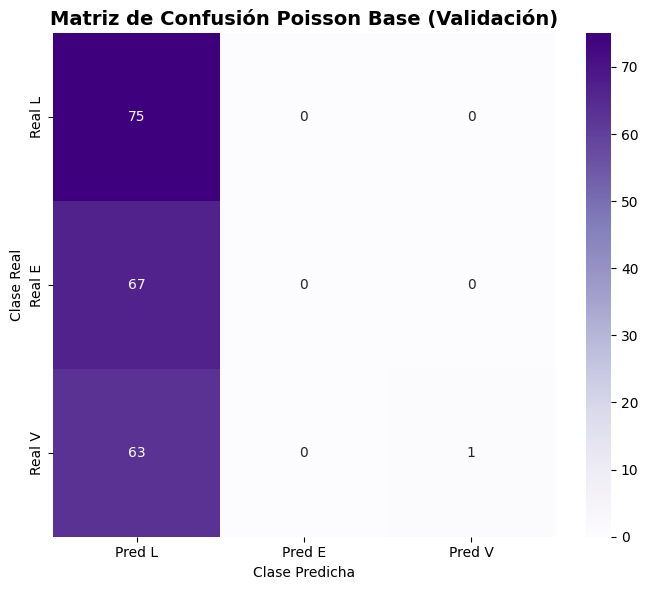

In [24]:
fig, ax = plt.subplots(
    figsize=(7, 6)
)

sns.heatmap(
    df_matriz_poisson_base,
    annot=True,
    fmt="d",
    cmap="Purples",
    ax=ax
)

ax.set_title(
    "Matriz de Confusión Poisson Base (Validación)",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel(
    "Clase Predicha"
)

ax.set_ylabel(
    "Clase Real"
)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR
    / "poisson_base_validacion.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Celda 22 Búsqueda del parámetro alpha
## 6. Ajuste de la regularización
Evalúo diferentes valores del parámetro `alpha`, encargado de controlar la regularización de los coeficientes de los dos regresores de Poisson.
Mantengo el mismo valor para el modelo local y visitante con el propósito de limitar la cantidad de configuraciones y reducir el riesgo de sobreajuste sobre el conjunto de validación.

Seleccionaré el valor utilizando principalmente la Deviance de Poisson promedio de ambos modelos, debido a que el objetivo directo de esta etapa es estimar goles y no optimizar directamente la clasificación L/E/V.

In [25]:
valores_alpha = [
    0.0,
    0.01,
    0.05,
    0.1,
    0.5,
    1.0,
    2.0,
    5.0
]

resultados_alpha = []
modelos_alpha = {}

# Celda 23 Evaluar los valores de alpha

In [26]:
for alpha in valores_alpha:

    modelo_local = Pipeline(
        steps=[
            (
                "preprocesamiento",
                preprocesador_poisson
            ),
            (
                "modelo",
                PoissonRegressor(
                    alpha=alpha,
                    max_iter=3000,
                    tol=1e-7
                )
            )
        ]
    )

    modelo_visitante = Pipeline(
        steps=[
            (
                "preprocesamiento",
                preprocesador_poisson
            ),
            (
                "modelo",
                PoissonRegressor(
                    alpha=alpha,
                    max_iter=3000,
                    tol=1e-7
                )
            )
        ]
    )

    modelo_local.fit(
        X_train,
        y_train_local
    )

    modelo_visitante.fit(
        X_train,
        y_train_visitante
    )

    lambda_l = modelo_local.predict(
        X_validacion
    )

    lambda_v = modelo_visitante.predict(
        X_validacion
    )

    dev_local = mean_poisson_deviance(
        y_validacion_local,
        lambda_l
    )

    dev_visitante = mean_poisson_deviance(
        y_validacion_visitante,
        lambda_v
    )

    mae_local = mean_absolute_error(
        y_validacion_local,
        lambda_l
    )

    mae_visitante = mean_absolute_error(
        y_validacion_visitante,
        lambda_v
    )

    pred_resultados = (
        generar_predicciones_poisson(
            lambda_l,
            lambda_v,
            df_validacion
        )
    )

    resultado_pred = (
        pred_resultados[
            "resultado_predicho"
        ]
        .to_numpy()
    )

    proba_pred = (
        pred_resultados[
            [
                "p_L",
                "p_E",
                "p_V"
            ]
        ]
        .to_numpy()
    )

    resultados_alpha.append({
        "alpha": alpha,

        "deviance_local":
            dev_local,

        "deviance_visitante":
            dev_visitante,

        "deviance_promedio":
            (
                dev_local
                + dev_visitante
            ) / 2,

        "mae_local":
            mae_local,

        "mae_visitante":
            mae_visitante,

        "mae_promedio":
            (
                mae_local
                + mae_visitante
            ) / 2,

        "accuracy_resultado":
            accuracy_score(
                y_val_resultado,
                resultado_pred
            ),

        "f1_macro_resultado":
            f1_score(
                y_val_resultado,
                resultado_pred,
                average="macro",
                zero_division=0
            ),

        "log_loss_resultado":
            log_loss(
                y_val_resultado,
                proba_pred,
                labels=[
                    "L",
                    "E",
                    "V"
                ]
            )
    })

    modelos_alpha[alpha] = {
        "local": modelo_local,
        "visitante":
            modelo_visitante
    }

C:\Users\ADMIN003\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_glm\glm.py:296: ConvergenceWarning: lbfgs failed to converge after 3000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=3000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result(
C:\Users\ADMIN003\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_glm\glm.py:296: ConvergenceWarning: lbfgs failed to converge after 3000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=3000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result(
C:\Users\ADMIN003\AppData\Local\Programs\Python\Python

# Celda 24  Ranking de alpha

In [27]:
df_alpha = (
    pd.DataFrame(
        resultados_alpha
    )
    .sort_values(
        [
            "deviance_promedio",
            "mae_promedio"
        ],
        ascending=[
            True,
            True
        ]
    )
    .reset_index(drop=True)
)

display(
    df_alpha.round(4)
)

,alpha,deviance_local,deviance_visitante,deviance_promedio,mae_local,mae_visitante,mae_promedio,accuracy_resultado,f1_macro_resultado,log_loss_resultado
0,0.50,1.2197,1.1398,1.1797,0.9331,0.7950,0.8640,0.3883,0.2539,1.1036
1,0.10,1.2217,1.1404,1.1811,0.9209,0.8094,0.8652,0.4078,0.3080,1.1007
2,1.00,1.2232,1.1428,1.1830,0.9375,0.7919,0.8647,0.3689,0.1888,1.1063
3,2.00,1.2264,1.1454,1.1859,0.9403,0.7911,0.8657,0.3641,0.1779,1.1085
4,0.05,1.2283,1.1468,1.1876,0.9190,0.8167,0.8679,0.4029,0.3081,1.1021
5,5.00,1.2291,1.1474,1.1882,0.9421,0.7925,0.8673,0.3641,0.1779,1.1102
6,0.01,1.2474,1.1689,1.2082,0.9179,0.8299,0.8739,0.3932,0.3243,1.1071
7,0.00,1.3218,1.4140,1.3679,0.9240,0.9796,0.9518,0.3738,0.3272,1.1330


# Celda 25 Selección preliminar

In [28]:
mejor_alpha = float(
    df_alpha.iloc[0][
        "alpha"
    ]
)

print(
    "Mejor alpha según Deviance promedio:",
    mejor_alpha
)

display(
    df_alpha.head(3).round(4)
)

Mejor alpha según Deviance promedio: 0.5


,alpha,deviance_local,deviance_visitante,deviance_promedio,mae_local,mae_visitante,mae_promedio,accuracy_resultado,f1_macro_resultado,log_loss_resultado
0,0.5,1.2197,1.1398,1.1797,0.9331,0.7950,0.8640,0.3883,0.2539,1.1036
1,0.1,1.2217,1.1404,1.1811,0.9209,0.8094,0.8652,0.4078,0.3080,1.1007
2,1.0,1.2232,1.1428,1.1830,0.9375,0.7919,0.8647,0.3689,0.1888,1.1063


# Celda 26 Corrección del orden de probabilidades
## 7. Corrección del orden de probabilidades para Log Loss
Durante la evaluación inicial identifiqué una advertencia relacionada con el orden de las clases utilizado por `log_loss`.

Las probabilidades generadas por mi función fueron almacenadas inicialmente en el orden `L`, `E`, `V`, mientras que `scikit-learn` ordena las etiquetas categóricas lexicográficamente como `E`, `L`, `V`.

Esta diferencia no afectó las predicciones de clase, las matrices de confusión ni las métricas de Accuracy, Precision, Recall y F1-Score. Sin embargo, sí podía producir un cálculo incorrecto del Log Loss.

Por esta razón reorganizo exclusivamente las columnas de probabilidad para esta métrica en el orden `E`, `L`, `V`.

In [29]:
proba_val_poisson_base_correcta = (
    pred_poisson_base[
        [
            "p_E",
            "p_L",
            "p_V"
        ]
    ]
    .to_numpy()
)

log_loss_base_corregido = log_loss(
    y_val_resultado,
    proba_val_poisson_base_correcta,
    labels=[
        "E",
        "L",
        "V"
    ]
)

print(
    "Log Loss Poisson base corregido:",
    round(
        log_loss_base_corregido,
        4
    )
)

Log Loss Poisson base corregido: 1.094


# Celda 27 Recalcular Log Loss de todos los valores de alpha

In [30]:
log_loss_corregidos = {}

for alpha in valores_alpha:

    modelo_local = (
        modelos_alpha[
            alpha
        ]["local"]
    )

    modelo_visitante = (
        modelos_alpha[
            alpha
        ]["visitante"]
    )

    lambda_l = modelo_local.predict(
        X_validacion
    )

    lambda_v = modelo_visitante.predict(
        X_validacion
    )

    pred_resultados = (
        generar_predicciones_poisson(
            lambda_l,
            lambda_v,
            df_validacion
        )
    )

    # Orden correcto:
    # E, L, V
    proba_correcta = (
        pred_resultados[
            [
                "p_E",
                "p_L",
                "p_V"
            ]
        ]
        .to_numpy()
    )

    loss_correcto = log_loss(
        y_val_resultado,
        proba_correcta,
        labels=[
            "E",
            "L",
            "V"
        ]
    )

    log_loss_corregidos[
        alpha
    ] = loss_correcto


df_alpha[
    "log_loss_resultado"
] = (
    df_alpha[
        "alpha"
    ]
    .map(
        log_loss_corregidos
    )
)

display(
    df_alpha.round(4)
)

,alpha,deviance_local,deviance_visitante,deviance_promedio,mae_local,mae_visitante,mae_promedio,accuracy_resultado,f1_macro_resultado,log_loss_resultado
0,0.50,1.2197,1.1398,1.1797,0.9331,0.7950,0.8640,0.3883,0.2539,1.0910
1,0.10,1.2217,1.1404,1.1811,0.9209,0.8094,0.8652,0.4078,0.3080,1.0877
2,1.00,1.2232,1.1428,1.1830,0.9375,0.7919,0.8647,0.3689,0.1888,1.0940
3,2.00,1.2264,1.1454,1.1859,0.9403,0.7911,0.8657,0.3641,0.1779,1.0963
4,0.05,1.2283,1.1468,1.1876,0.9190,0.8167,0.8679,0.4029,0.3081,1.0893
5,5.00,1.2291,1.1474,1.1882,0.9421,0.7925,0.8673,0.3641,0.1779,1.0982
6,0.01,1.2474,1.1689,1.2082,0.9179,0.8299,0.8739,0.3932,0.3243,1.0955
7,0.00,1.3218,1.4140,1.3679,0.9240,0.9796,0.9518,0.3738,0.3272,1.1397


# Celda 28 Comprobar convergencia
### 7.1. Verificación de convergencia
Durante la búsqueda de regularización algunas configuraciones alcanzaron el límite máximo de iteraciones del optimizador.
Compruebo el número de iteraciones utilizado por cada regresor para identificar qué configuraciones no alcanzaron convergencia completa.
No utilizaré como configuración definitiva un modelo que haya alcanzado el límite de iteraciones sin converger.

In [31]:
convergencia_alpha = []

for alpha in valores_alpha:

    modelo_local = (
        modelos_alpha[
            alpha
        ]["local"]
        .named_steps[
            "modelo"
        ]
    )

    modelo_visitante = (
        modelos_alpha[
            alpha
        ]["visitante"]
        .named_steps[
            "modelo"
        ]
    )

    iter_local = int(
        modelo_local.n_iter_
    )

    iter_visitante = int(
        modelo_visitante.n_iter_
    )

    convergencia_alpha.append({
        "alpha":
            alpha,

        "iteraciones_local":
            iter_local,

        "iteraciones_visitante":
            iter_visitante,

        "local_alcanzo_limite":
            iter_local >= 3000,

        "visitante_alcanzo_limite":
            iter_visitante >= 3000
    })

df_convergencia = pd.DataFrame(
    convergencia_alpha
)

display(
    df_convergencia
)

,alpha,iteraciones_local,iteraciones_visitante,local_alcanzo_limite,visitante_alcanzo_limite
0,0.00,3000,3000,True,True
1,0.01,115,112,False,False
2,0.05,56,52,False,False
3,0.10,45,37,False,False
4,0.50,21,21,False,False
5,1.00,13,12,False,False
6,2.00,12,12,False,False
7,5.00,12,9,False,False


# Celda 29 Evaluación completa de alpha = 0.5
## 8. Evaluación de la configuración seleccionada

De acuerdo con la Deviance de Poisson promedio, selecciono `alpha = 0.5` como configuración para los dos regresores.

Antes de realizar la evaluación final sobre prueba analizo detalladamente esta configuración sobre validación, incluyendo el error en goles, la clasificación derivada del resultado, el marcador exacto y la distribución de las predicciones.

In [32]:
ALPHA_FINAL = 0.5

modelo_poisson_local_seleccionado = (
    modelos_alpha[
        ALPHA_FINAL
    ]["local"]
)

modelo_poisson_visitante_seleccionado = (
    modelos_alpha[
        ALPHA_FINAL
    ]["visitante"]
)

lambda_local_val_final = (
    modelo_poisson_local_seleccionado
    .predict(
        X_validacion
    )
)

lambda_visitante_val_final = (
    modelo_poisson_visitante_seleccionado
    .predict(
        X_validacion
    )
)

print(
    "Lambda local:"
)

print(
    "mínimo:",
    round(
        lambda_local_val_final.min(),
        4
    )
)

print(
    "promedio:",
    round(
        lambda_local_val_final.mean(),
        4
    )
)

print(
    "máximo:",
    round(
        lambda_local_val_final.max(),
        4
    )
)

print()

print(
    "Lambda visitante:"
)

print(
    "mínimo:",
    round(
        lambda_visitante_val_final.min(),
        4
    )
)

print(
    "promedio:",
    round(
        lambda_visitante_val_final.mean(),
        4
    )
)

print(
    "máximo:",
    round(
        lambda_visitante_val_final.max(),
        4
    )
)

Lambda local:
mínimo: 1.0293
promedio: 1.1801
máximo: 1.3763

Lambda visitante:
mínimo: 0.896
promedio: 1.0096
máximo: 1.1585


# Celda 30 Métricas de goles seleccionadas

In [34]:
metricas_goles_poisson_final = pd.DataFrame({
    "Objetivo": [
        "Goles local",
        "Goles visitante"
    ],

    "MAE": [
        mean_absolute_error(
            y_validacion_local,
            lambda_local_val_final
        ),

        mean_absolute_error(
            y_validacion_visitante,
            lambda_visitante_val_final
        )
    ],

    "RMSE": [
        np.sqrt(
            mean_squared_error(
                y_validacion_local,
                lambda_local_val_final
            )
        ),

        np.sqrt(
            mean_squared_error(
                y_validacion_visitante,
                lambda_visitante_val_final
            )
        )
    ],

    "Poisson Deviance": [
        mean_poisson_deviance(
            y_validacion_local,
            lambda_local_val_final
        ),

        mean_poisson_deviance(
            y_validacion_visitante,
            lambda_visitante_val_final
        )
    ]
})

display(
    metricas_goles_poisson_final.round(4)
)

,Objetivo,MAE,RMSE,Poisson Deviance
0,Goles local,0.9331,1.1709,1.2197
1,Goles visitante,0.7950,1.0351,1.1398


# Celda 31 Resultado L/E/V de alpha=0.5

In [35]:
pred_poisson_final_val = (
    generar_predicciones_poisson(
        lambda_local_val_final,
        lambda_visitante_val_final,
        df_validacion
    )
)

pred_resultado_final_val = (
    pred_poisson_final_val[
        "resultado_predicho"
    ]
    .to_numpy()
)

proba_resultado_final_val = (
    pred_poisson_final_val[
        [
            "p_E",
            "p_L",
            "p_V"
        ]
    ]
    .to_numpy()
)


metricas_poisson_val_final = {
    "accuracy": accuracy_score(
        y_val_resultado,
        pred_resultado_final_val
    ),

    "precision_macro": precision_score(
        y_val_resultado,
        pred_resultado_final_val,
        average="macro",
        zero_division=0
    ),

    "recall_macro": recall_score(
        y_val_resultado,
        pred_resultado_final_val,
        average="macro",
        zero_division=0
    ),

    "f1_macro": f1_score(
        y_val_resultado,
        pred_resultado_final_val,
        average="macro",
        zero_division=0
    ),

    "log_loss": log_loss(
        y_val_resultado,
        proba_resultado_final_val,
        labels=[
            "E",
            "L",
            "V"
        ]
    )
}

for metrica, valor in (
    metricas_poisson_val_final.items()
):
    print(
        f"{metrica}: {valor:.4f}"
    )

accuracy: 0.3883
precision_macro: 0.3239
recall_macro: 0.3624
f1_macro: 0.2539
log_loss: 1.0910


# Celda 32 Reporte por clase y matriz de confusión

In [36]:
reporte_poisson_val = classification_report(
    y_val_resultado,
    pred_resultado_final_val,
    labels=[
        "L",
        "E",
        "V"
    ],
    output_dict=True,
    zero_division=0
)

display(
    pd.DataFrame(
        reporte_poisson_val
    )
    .T
    .round(4)
)

,precision,recall,f1-score,support
L,0.3717,0.9467,0.5338,75.0000
E,0.0000,0.0000,0.0000,67.0000
V,0.6000,0.1406,0.2278,64.0000
accuracy,0.3883,0.3883,0.3883,0.3883
macro avg,0.3239,0.3624,0.2539,206.0000
weighted avg,0.3217,0.3883,0.2651,206.0000


In [37]:
matriz_poisson_final_val = confusion_matrix(
    y_val_resultado,
    pred_resultado_final_val,
    labels=[
        "L",
        "E",
        "V"
    ]
)

df_matriz_poisson_final_val = pd.DataFrame(
    matriz_poisson_final_val,
    index=[
        "Real L",
        "Real E",
        "Real V"
    ],
    columns=[
        "Pred L",
        "Pred E",
        "Pred V"
    ]
)

display(
    df_matriz_poisson_final_val
)

,Pred L,Pred E,Pred V
Real L,71,0,4
Real E,65,0,2
Real V,55,0,9


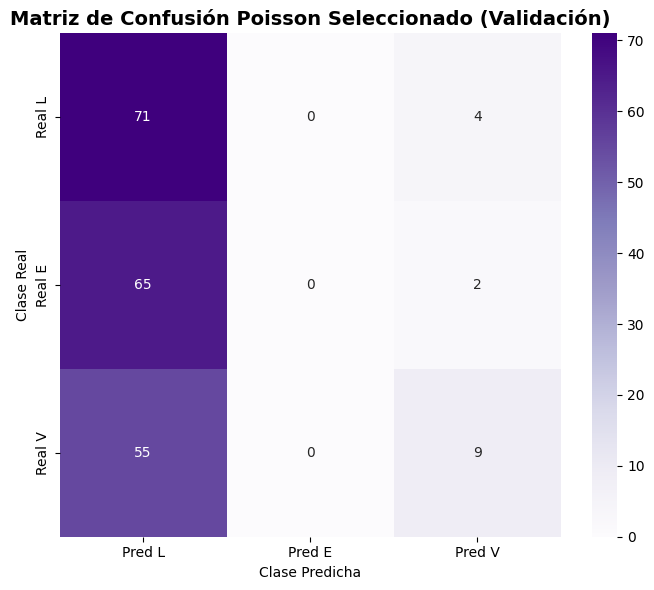

In [38]:
fig, ax = plt.subplots(
    figsize=(7, 6)
)

sns.heatmap(
    df_matriz_poisson_final_val,
    annot=True,
    fmt="d",
    cmap="Purples",
    ax=ax
)

ax.set_title(
    "Matriz de Confusión Poisson Seleccionado (Validación)",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel(
    "Clase Predicha"
)

ax.set_ylabel(
    "Clase Real"
)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR
    / "poisson_seleccionado_validacion.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Celda 33 Distribución de resultados predichos

In [40]:
distribucion_poisson_val = pd.DataFrame({
    "Real": (
        pd.Series(
            y_val_resultado
        )
        .value_counts()
        .reindex(
            [
                "L",
                "E",
                "V"
            ],
            fill_value=0
        )
    ),

    "Predicho": (
        pd.Series(
            pred_resultado_final_val
        )
        .value_counts()
        .reindex(
            [
                "L",
                "E",
                "V"
            ],
            fill_value=0
        )
    )
})

display(
    distribucion_poisson_val
)

,Real,Predicho
L,75,191
E,67,0
V,64,15


# Celda 34 Exactitud del marcador del modelo seleccionado

In [41]:
marcador_correcto_poisson_val = (
    (
        pred_poisson_final_val[
            "marcador_local_pred"
        ].to_numpy()
        ==
        y_validacion_local.to_numpy()
    )
    &
    (
        pred_poisson_final_val[
            "marcador_visitante_pred"
        ].to_numpy()
        ==
        y_validacion_visitante.to_numpy()
    )
)

accuracy_marcador_poisson_val = (
    marcador_correcto_poisson_val.mean()
)

print(
    "Accuracy marcador exacto:",
    f"{accuracy_marcador_poisson_val * 100:.2f}%"
)

print(
    "Marcadores acertados:",
    marcador_correcto_poisson_val.sum(),
    "de",
    len(
        marcador_correcto_poisson_val
    )
)

Accuracy marcador exacto: 10.68%
Marcadores acertados: 22 de 206


# Celda 35 Marcador exacto del baseline frente al modelo

In [42]:
marcador_baseline_local = (
    pred_poisson_baseline[
        "marcador_local_pred"
    ]
    .to_numpy()
)

marcador_baseline_visitante = (
    pred_poisson_baseline[
        "marcador_visitante_pred"
    ]
    .to_numpy()
)

acierto_marcador_baseline = (
    (
        marcador_baseline_local
        ==
        y_validacion_local.to_numpy()
    )
    &
    (
        marcador_baseline_visitante
        ==
        y_validacion_visitante.to_numpy()
    )
)

comparacion_marcador = pd.DataFrame({
    "Modelo": [
        "Poisson constante",
        "Poisson con características"
    ],

    "Accuracy marcador exacto": [
        acierto_marcador_baseline.mean(),
        accuracy_marcador_poisson_val
    ],

    "Marcadores acertados": [
        acierto_marcador_baseline.sum(),
        marcador_correcto_poisson_val.sum()
    ]
})

display(
    comparacion_marcador.round(4)
)

,Modelo,Accuracy marcador exacto,Marcadores acertados
0,Poisson constante,0.1214,25
1,Poisson con características,0.1068,22


# Celda 36 Congelar configuración definitiva
## 9. Selección definitiva del parámetro de regularización

Después de evaluar diferentes niveles de regularización selecciono `alpha = 0.5` como configuración definitiva de los modelos de Poisson.

Esta decisión se basa en la Deviance de Poisson promedio, debido a que el objetivo directo de estos regresores es estimar la cantidad esperada de goles del equipo local y visitante.

La configuración seleccionada obtuvo una Deviance promedio de 1.1797 y convergió correctamente en 21 iteraciones para ambos modelos.

Aunque otros valores de `alpha` obtuvieron mejores métricas al derivar posteriormente las categorías victoria, empate y derrota, no utilizo esas métricas como criterio principal de selección para evitar convertir el modelo de goles en un clasificador ajustado indirectamente.

A partir de este punto considero congelada la configuración y no realizaré modificaciones en función de los resultados del conjunto de prueba.

In [43]:
ALPHA_FINAL = 0.5

print(
    "Alpha definitivo:",
    ALPHA_FINAL
)

Alpha definitivo: 0.5


# Celda 37 Preparar entrenamiento final
## 10. Entrenamiento definitivo de los modelos Poisson
Después de seleccionar el nivel de regularización, uno los conjuntos de entrenamiento y validación para utilizar todos los partidos históricos disponibles hasta finales de 2025.

El conjunto resultante contiene 2,075 encuentros. Mantengo completamente separados los 151 partidos correspondientes a 2026 y 2026/2027, que serán utilizados únicamente para la evaluación final.

In [44]:
df_train_final = pd.concat(
    [
        df_train,
        df_validacion
    ],
    ignore_index=True
)

df_train_final = (
    df_train_final
    .sort_values(
        [
            "fecha_partido",
            "registro_id"
        ]
    )
    .reset_index(drop=True)
)

X_train_final = (
    df_train_final[
        columnas_X
    ].copy()
)

y_train_final_local = (
    df_train_final[
        "home_team_goal_count"
    ].copy()
)

y_train_final_visitante = (
    df_train_final[
        "away_team_goal_count"
    ].copy()
)

print(
    "Partidos entrenamiento final:",
    len(df_train_final)
)

print(
    "X_train_final:",
    X_train_final.shape
)

print(
    "Fecha máxima entrenamiento:",
    df_train_final[
        "fecha_partido"
    ].max()
)

print(
    "Fecha mínima prueba:",
    df_test[
        "fecha_partido"
    ].min()
)

Partidos entrenamiento final: 2075
X_train_final: (2075, 48)
Fecha máxima entrenamiento: 2025-11-29 00:00:00
Fecha mínima prueba: 2026-01-16 00:00:00


# Celda 38 Entrenar Poisson definitivo

In [45]:
from sklearn.base import clone

modelo_poisson_local_final = Pipeline(
    steps=[
        (
            "preprocesamiento",
            clone(
                preprocesador_poisson
            )
        ),
        (
            "modelo",
            PoissonRegressor(
                alpha=ALPHA_FINAL,
                max_iter=3000,
                tol=1e-7
            )
        )
    ]
)

modelo_poisson_visitante_final = Pipeline(
    steps=[
        (
            "preprocesamiento",
            clone(
                preprocesador_poisson
            )
        ),
        (
            "modelo",
            PoissonRegressor(
                alpha=ALPHA_FINAL,
                max_iter=3000,
                tol=1e-7
            )
        )
    ]
)

modelo_poisson_local_final.fit(
    X_train_final,
    y_train_final_local
)

modelo_poisson_visitante_final.fit(
    X_train_final,
    y_train_final_visitante
)

print(
    "Modelos Poisson definitivos entrenados."
)

print(
    "Iteraciones modelo local:",
    modelo_poisson_local_final
    .named_steps["modelo"]
    .n_iter_
)

print(
    "Iteraciones modelo visitante:",
    modelo_poisson_visitante_final
    .named_steps["modelo"]
    .n_iter_
)

Modelos Poisson definitivos entrenados.
Iteraciones modelo local: 21
Iteraciones modelo visitante: 12


# Celda 39 Primera y única predicción sobre prueba
## 11. Evaluación final sobre el conjunto de prueba
Evalúo por primera y única vez los dos modelos de Poisson definitivos utilizando los 151 partidos reservados como prueba.
Primero analizo la estimación de goles mediante MAE, RMSE y Deviance de Poisson. Posteriormente transformo las tasas de gol estimadas en distribuciones probabilísticas de marcadores y derivo las probabilidades de victoria local, empate y victoria visitante.
Después de esta evaluación no realizaré modificaciones adicionales en los modelos basadas en el conjunto de prueba.

In [46]:
lambda_local_test = (
    modelo_poisson_local_final.predict(
        X_test
    )
)

lambda_visitante_test = (
    modelo_poisson_visitante_final.predict(
        X_test
    )
)

print(
    "Lambda local:"
)

print(
    "mínimo:",
    round(
        lambda_local_test.min(),
        4
    )
)

print(
    "promedio:",
    round(
        lambda_local_test.mean(),
        4
    )
)

print(
    "máximo:",
    round(
        lambda_local_test.max(),
        4
    )
)

print()

print(
    "Lambda visitante:"
)

print(
    "mínimo:",
    round(
        lambda_visitante_test.min(),
        4
    )
)

print(
    "promedio:",
    round(
        lambda_visitante_test.mean(),
        4
    )
)

print(
    "máximo:",
    round(
        lambda_visitante_test.max(),
        4
    )
)

Lambda local:
mínimo: 1.0509
promedio: 1.1974
máximo: 1.3876

Lambda visitante:
mínimo: 0.896
promedio: 1.0285
máximo: 1.1368


# Celda 40 Métricas finales de goles

In [47]:
metricas_goles_poisson_test = pd.DataFrame({
    "Objetivo": [
        "Goles local",
        "Goles visitante"
    ],

    "MAE": [
        mean_absolute_error(
            y_test_local,
            lambda_local_test
        ),

        mean_absolute_error(
            y_test_visitante,
            lambda_visitante_test
        )
    ],

    "RMSE": [
        np.sqrt(
            mean_squared_error(
                y_test_local,
                lambda_local_test
            )
        ),

        np.sqrt(
            mean_squared_error(
                y_test_visitante,
                lambda_visitante_test
            )
        )
    ],

    "Poisson Deviance": [
        mean_poisson_deviance(
            y_test_local,
            lambda_local_test
        ),

        mean_poisson_deviance(
            y_test_visitante,
            lambda_visitante_test
        )
    ]
})

display(
    metricas_goles_poisson_test.round(4)
)

,Objetivo,MAE,RMSE,Poisson Deviance
0,Goles local,0.9557,1.2944,1.2547
1,Goles visitante,0.8187,1.0757,1.1674


# Celda 41 Generar probabilidades y marcador final

In [48]:
pred_poisson_test = (
    generar_predicciones_poisson(
        lambda_local_test,
        lambda_visitante_test,
        df_test
    )
)

display(
    pred_poisson_test.head()
)

,registro_id,lambda_local,lambda_visitante,p_L,p_E,p_V,resultado_predicho,marcador_local_pred,marcador_visitante_pred,masa_cubierta
0,LPF_02077,1.191057,1.028866,0.396370,0.288498,0.315132,L,1,1,1.0
1,LPF_02078,1.138145,1.099100,0.365589,0.288337,0.346074,L,1,1,1.0
2,LPF_02079,1.243136,0.970461,0.424867,0.286702,0.288431,L,1,0,1.0
3,LPF_02080,1.237106,0.973284,0.422472,0.287173,0.290355,L,1,0,1.0
4,LPF_02081,1.187651,1.030671,0.394978,0.288701,0.316320,L,1,1,1.0


# Celda 42 Evaluación L/E/V derivada
### 11.1. Evaluación del resultado derivado

Aunque Poisson fue entrenado para estimar goles, utilizo las distribuciones obtenidas para calcular probabilidades de victoria local, empate y victoria visitante.

Esta evaluación permite realizar una comparación complementaria con los clasificadores supervisados. Sin embargo, mantengo la distinción metodológica: Poisson no fue entrenado directamente para maximizar la clasificación del resultado.

In [49]:
y_test_resultado = (
    df_test[
        "resultado"
    ]
    .to_numpy()
)

pred_test_resultado_poisson = (
    pred_poisson_test[
        "resultado_predicho"
    ]
    .to_numpy()
)

# Orden lexicográfico requerido:
# E, L, V
proba_test_poisson = (
    pred_poisson_test[
        [
            "p_E",
            "p_L",
            "p_V"
        ]
    ]
    .to_numpy()
)

metricas_resultado_poisson_test = {
    "accuracy": accuracy_score(
        y_test_resultado,
        pred_test_resultado_poisson
    ),

    "precision_macro": precision_score(
        y_test_resultado,
        pred_test_resultado_poisson,
        average="macro",
        zero_division=0
    ),

    "recall_macro": recall_score(
        y_test_resultado,
        pred_test_resultado_poisson,
        average="macro",
        zero_division=0
    ),

    "f1_macro": f1_score(
        y_test_resultado,
        pred_test_resultado_poisson,
        average="macro",
        zero_division=0
    ),

    "log_loss": log_loss(
        y_test_resultado,
        proba_test_poisson,
        labels=[
            "E",
            "L",
            "V"
        ]
    )
}

for metrica, valor in (
    metricas_resultado_poisson_test.items()
):
    print(
        f"{metrica}: {valor:.4f}"
    )

accuracy: 0.3709
precision_macro: 0.2655
recall_macro: 0.3433
f1_macro: 0.2232
log_loss: 1.0928


# Celda 43 Reporte por categoría

In [50]:
reporte_poisson_test = (
    classification_report(
        y_test_resultado,
        pred_test_resultado_poisson,
        labels=[
            "L",
            "E",
            "V"
        ],
        output_dict=True,
        zero_division=0
    )
)

df_reporte_poisson_test = (
    pd.DataFrame(
        reporte_poisson_test
    )
    .T
)

display(
    df_reporte_poisson_test.round(4)
)

,precision,recall,f1-score,support
L,0.3681,0.9464,0.5300,56.0000
E,0.0000,0.0000,0.0000,59.0000
V,0.4286,0.0833,0.1395,36.0000
accuracy,0.3709,0.3709,0.3709,0.3709
macro avg,0.2655,0.3433,0.2232,151.0000
weighted avg,0.2387,0.3709,0.2298,151.0000


# Celda 44 Matriz de confusión final

In [51]:
matriz_poisson_test = confusion_matrix(
    y_test_resultado,
    pred_test_resultado_poisson,
    labels=[
        "L",
        "E",
        "V"
    ]
)

df_matriz_poisson_test = pd.DataFrame(
    matriz_poisson_test,
    index=[
        "Real L",
        "Real E",
        "Real V"
    ],
    columns=[
        "Pred L",
        "Pred E",
        "Pred V"
    ]
)

display(
    df_matriz_poisson_test
)

,Pred L,Pred E,Pred V
Real L,53,0,3
Real E,58,0,1
Real V,33,0,3


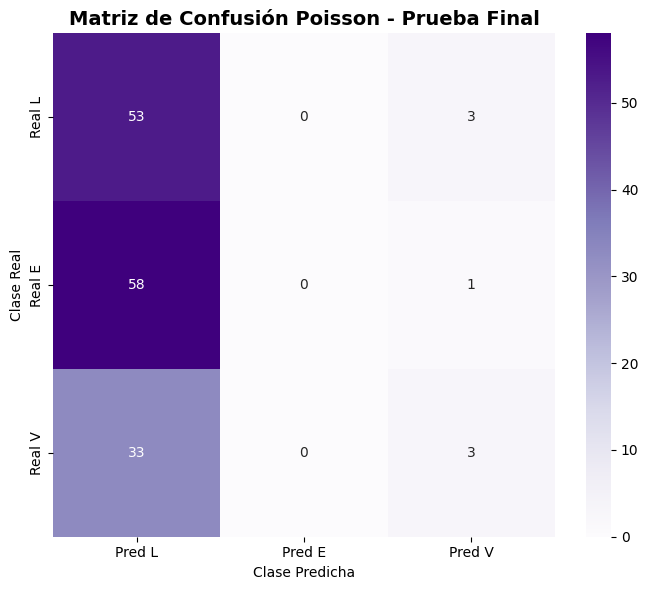

In [52]:
fig, ax = plt.subplots(
    figsize=(7, 6)
)

sns.heatmap(
    df_matriz_poisson_test,
    annot=True,
    fmt="d",
    cmap="Purples",
    ax=ax
)

ax.set_title(
    "Matriz de Confusión Poisson - Prueba Final",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel(
    "Clase Predicha"
)

ax.set_ylabel(
    "Clase Real"
)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR
    / "poisson_prueba_final.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Celda 45 Distribución real y predicha

In [53]:
distribucion_poisson_test = pd.DataFrame({
    "Real": (
        pd.Series(
            y_test_resultado
        )
        .value_counts()
        .reindex(
            ["L", "E", "V"],
            fill_value=0
        )
    ),

    "Predicho": (
        pd.Series(
            pred_test_resultado_poisson
        )
        .value_counts()
        .reindex(
            ["L", "E", "V"],
            fill_value=0
        )
    )
})

display(
    distribucion_poisson_test
)

,Real,Predicho
L,56,144
E,59,0
V,36,7


# Celda 46 Exactitud del marcador final

In [54]:
marcador_poisson_test_correcto = (
    (
        pred_poisson_test[
            "marcador_local_pred"
        ].to_numpy()
        ==
        y_test_local.to_numpy()
    )
    &
    (
        pred_poisson_test[
            "marcador_visitante_pred"
        ].to_numpy()
        ==
        y_test_visitante.to_numpy()
    )
)

accuracy_marcador_poisson_test = (
    marcador_poisson_test_correcto.mean()
)

print(
    "Accuracy marcador exacto:",
    f"{accuracy_marcador_poisson_test * 100:.2f}%"
)

print(
    "Marcadores acertados:",
    marcador_poisson_test_correcto.sum(),
    "de",
    len(
        marcador_poisson_test_correcto
    )
)

Accuracy marcador exacto: 16.56%
Marcadores acertados: 25 de 151


# Celda 47 Baseline Poisson final

In [55]:
lambda_local_baseline_final = (
    y_train_final_local.mean()
)

lambda_visitante_baseline_final = (
    y_train_final_visitante.mean()
)

lambda_local_baseline_test = np.full(
    len(df_test),
    lambda_local_baseline_final
)

lambda_visitante_baseline_test = np.full(
    len(df_test),
    lambda_visitante_baseline_final
)

pred_poisson_baseline_test = (
    generar_predicciones_poisson(
        lambda_local_baseline_test,
        lambda_visitante_baseline_test,
        df_test
    )
)

print(
    "Lambda local baseline final:",
    round(
        lambda_local_baseline_final,
        4
    )
)

print(
    "Lambda visitante baseline final:",
    round(
        lambda_visitante_baseline_final,
        4
    )
)

Lambda local baseline final: 1.1961
Lambda visitante baseline final: 1.0337


# Celda 48 Comparación de goles: constante vs. características

In [56]:
comparacion_goles_test = pd.DataFrame({
    "Modelo": [
        "Poisson constante",
        "Poisson con características"
    ],

    "MAE local": [
        mean_absolute_error(
            y_test_local,
            lambda_local_baseline_test
        ),
        mean_absolute_error(
            y_test_local,
            lambda_local_test
        )
    ],

    "MAE visitante": [
        mean_absolute_error(
            y_test_visitante,
            lambda_visitante_baseline_test
        ),
        mean_absolute_error(
            y_test_visitante,
            lambda_visitante_test
        )
    ],

    "Deviance local": [
        mean_poisson_deviance(
            y_test_local,
            lambda_local_baseline_test
        ),
        mean_poisson_deviance(
            y_test_local,
            lambda_local_test
        )
    ],

    "Deviance visitante": [
        mean_poisson_deviance(
            y_test_visitante,
            lambda_visitante_baseline_test
        ),
        mean_poisson_deviance(
            y_test_visitante,
            lambda_visitante_test
        )
    ]
})

display(
    comparacion_goles_test.round(4)
)

,Modelo,MAE local,MAE visitante,Deviance local,Deviance visitante
0,Poisson constante,0.9688,0.8184,1.2899,1.1770
1,Poisson con características,0.9557,0.8187,1.2547,1.1674


# Celda 49 Comparación de marcador exacto en prueba

In [57]:
marcador_baseline_test_correcto = (
    (
        pred_poisson_baseline_test[
            "marcador_local_pred"
        ].to_numpy()
        ==
        y_test_local.to_numpy()
    )
    &
    (
        pred_poisson_baseline_test[
            "marcador_visitante_pred"
        ].to_numpy()
        ==
        y_test_visitante.to_numpy()
    )
)

comparacion_marcador_test = pd.DataFrame({
    "Modelo": [
        "Poisson constante",
        "Poisson con características"
    ],

    "Accuracy marcador exacto": [
        marcador_baseline_test_correcto.mean(),
        accuracy_marcador_poisson_test
    ],

    "Marcadores acertados": [
        marcador_baseline_test_correcto.sum(),
        marcador_poisson_test_correcto.sum()
    ]
})

display(
    comparacion_marcador_test.round(4)
)

,Modelo,Accuracy marcador exacto,Marcadores acertados
0,Poisson constante,0.1589,24
1,Poisson con características,0.1656,25


# Celda 50  Comparación complementaria con clasificadores

In [58]:
comparacion_resultado_final = pd.DataFrame({
    "Modelo": [
        "Regresión Logística",
        "Random Forest",
        "XGBoost",
        "Poisson (resultado derivado)"
    ],

    "Accuracy": [
        0.3642,
        0.3576,
        0.3974,
        metricas_resultado_poisson_test[
            "accuracy"
        ]
    ],

    "Precision Macro": [
        0.3876,
        0.3593,
        0.4028,
        metricas_resultado_poisson_test[
            "precision_macro"
        ]
    ],

    "Recall Macro": [
        0.3824,
        0.3842,
        0.3941,
        metricas_resultado_poisson_test[
            "recall_macro"
        ]
    ],

    "F1 Macro": [
        0.3673,
        0.3539,
        0.3587,
        metricas_resultado_poisson_test[
            "f1_macro"
        ]
    ],

    "Log Loss": [
        1.0910,
        1.0862,
        1.0836,
        metricas_resultado_poisson_test[
            "log_loss"
        ]
    ]
})

display(
    comparacion_resultado_final.round(4)
)

,Modelo,Accuracy,Precision Macro,Recall Macro,F1 Macro,Log Loss
0,Regresión Logística,0.3642,0.3876,0.3824,0.3673,1.0910
1,Random Forest,0.3576,0.3593,0.3842,0.3539,1.0862
2,XGBoost,0.3974,0.4028,0.3941,0.3587,1.0836
3,Poisson (resultado derivado),0.3709,0.2655,0.3433,0.2232,1.0928


# Celda 51 Guardar los dos modelos
## 12. Almacenamiento de los modelos Poisson
Finalmente almaceno los dos Pipelines de regresión utilizados para estimar los goles del equipo local y visitante.

Mantengo ambos modelos separados porque cada uno representa una variable objetivo diferente. Durante la implementación del sistema utilizaré conjuntamente sus tasas estimadas para construir la matriz de probabilidades de marcadores y derivar las probabilidades de victoria local, empate y victoria visitante.

In [59]:
import joblib

RUTA_POISSON_LOCAL = (
    MODELS_DIR
    / "poisson_local_lpf.joblib"
)

RUTA_POISSON_VISITANTE = (
    MODELS_DIR
    / "poisson_visitante_lpf.joblib"
)

joblib.dump(
    modelo_poisson_local_final,
    RUTA_POISSON_LOCAL
)

joblib.dump(
    modelo_poisson_visitante_final,
    RUTA_POISSON_VISITANTE
)

print(
    "Modelo local:",
    RUTA_POISSON_LOCAL
)

print(
    "Existe:",
    RUTA_POISSON_LOCAL.exists()
)

print()

print(
    "Modelo visitante:",
    RUTA_POISSON_VISITANTE
)

print(
    "Existe:",
    RUTA_POISSON_VISITANTE.exists()
)

Modelo local: C:\Users\ADMIN003\OneDrive - Universidad Tecnológica de Panamá\Escritorio\II SEMESTRE 2026\TESIS\Sistema_Predictivo_LPF\models\poisson_local_lpf.joblib
Existe: True

Modelo visitante: C:\Users\ADMIN003\OneDrive - Universidad Tecnológica de Panamá\Escritorio\II SEMESTRE 2026\TESIS\Sistema_Predictivo_LPF\models\poisson_visitante_lpf.joblib
Existe: True


## 13. Conclusión del modelo basado en Poisson

Implementé dos modelos de Regresión de Poisson independientes para estimar los goles esperados del equipo local y visitante. Después de evaluar distintos niveles de regularización seleccioné `alpha = 0.5`, debido a que obtuvo la menor Deviance de Poisson promedio sobre el conjunto de validación y alcanzó convergencia correctamente.

Posteriormente reentrené ambos modelos utilizando los 2,075 partidos disponibles hasta finales de 2025 y realicé una única evaluación sobre los 151 encuentros reservados como prueba.

Para los goles del equipo local obtuve un MAE de 0.9557, RMSE de 1.2944 y Deviance de Poisson de 1.2547. Para el equipo visitante los valores fueron 0.8187, 1.0757 y 1.1674, respectivamente.

Al comparar estos resultados con un modelo Poisson constante basado únicamente en los promedios históricos, las características prepartido redujeron la Deviance local de 1.2899 a 1.2547 y la visitante de 1.1770 a 1.1674. La mejora fue moderada, pero indica que las características históricas aportaron información adicional para la estimación de los conteos de goles.

A partir de las tasas estimadas construí matrices de probabilidades de marcadores entre 0 y 10 goles. El marcador exacto con mayor probabilidad coincidió con el resultado observado en 25 de los 151 partidos, equivalente a una exactitud de 16.56 %. El modelo Poisson constante acertó 24 encuentros, correspondiente a 15.89 %.

También derivé probabilidades de victoria local, empate y victoria visitante mediante la agregación de las matrices de marcadores. Esta clasificación obtuvo un Accuracy de 37.09 %, Precision Macro de 26.55 %, Recall Macro de 34.33 %, F1-Score Macro de 22.32 % y Log Loss de 1.0928.

El principal inconveniente fue que ninguna de las predicciones seleccionó el empate como clase de máxima probabilidad. Aunque el modelo asignó probabilidades apreciables a esta categoría, generalmente cercanas al 28–29 % en numerosos encuentros, la probabilidad de victoria local o visitante resultó superior. Como consecuencia, 144 de los 151 partidos fueron clasificados como victoria local y solamente 7 como victoria visitante.

Por esta razón no utilizaré Poisson como clasificador principal del resultado L/E/V. Su función dentro del sistema será complementaria: estimar los goles esperados, generar una distribución probabilística de posibles marcadores y proporcionar probabilidades de resultado derivadas de dicha distribución.

Los resultados de Poisson se analizarán conjuntamente con Regresión Logística, Random Forest y XGBoost durante la etapa de comparación y selección de los modelos.